# 05 · Next best action: cross-sell and reactivation for at-risk customers

The model says **who** is at risk; SHAP says **why**. We map each targeted
customer's strongest *actionable* risk driver to an offer.

> These are rule-based business hypotheses, not proven effects. Each offer
> family should become its own arm in the A/B test from notebook 04.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.config import load_config, path, set_seed
from src.data import FEATURES
from src.recommend import assign_actions, family_shap, rules_table
from src.plots import ACCENT, GOOD, MUTED, NEUTRAL, RISK, save, save_table, setup_style

cfg = load_config()
SEED = set_seed()
setup_style()
pd.set_option("display.width", 180, "display.max_columns", 30, "display.max_colwidth", 70)

test = pd.read_csv(path("processed") / "test_with_business.csv")
shap_values = np.load(path("processed") / "test_shap_values.npy")
assert len(test) == len(shap_values)

## 1. Rule table: driver family → offer
Per-feature SHAP values are summed into four **actionable** families
(demographics are excluded — we can't change them). The dominant family
gives the **primary** offer; the strongest remaining family, if it adds at
least 0.25 log-odds of risk, gives a **secondary** offer.

In [2]:
rules = rules_table()
save_table(rules, "nba_rules")
rules[["driver family", "condition", "action family", "offer", "rationale"]]

,driver family,condition,action family,offer,rationale
0,usage,usage:frequency,Reactivation,Spend challenge: cashback for N transactions in 60 days,Few or falling transactions: the card is not top-of-wallet
1,usage,usage:amount,Reactivation,Category cashback on the customer's top spend category,Spend pattern (amount / ticket size) signals the card is losing sh...
2,usage,usage:inactivity,Reactivation,Re-engagement push + small activation bonus,Inactivity streak: reach out before the account goes dormant
3,products,products,Cross-sell,Second product: savings account / debit card / insurance bundle,Few products: low switching cost; another product raises stickiness
4,balance,balance:zero,Cross-sell,Instalment plan / 0% balance-transfer offer,Never carries a balance: a low-value 'backup' card
5,balance,balance:maxed,Credit,Credit-limit review / debt-restructuring offer,Balance at the limit: possible financial stress or debt moved else...
6,balance,balance:other,Credit,Personalised rate or limit offer,Revolving behaviour adds to risk
7,service,service,Service recovery,Proactive call from a senior agent to resolve open issues,Many contacts with the bank often mean unresolved problems


## 2. Assign actions to every targeted customer

In [3]:
mask = test["target"].to_numpy() == 1
cols = ["clientnum", "proba", "clv", "expected_profit", "churned",
        "total_trans_ct", "total_ct_chng_q4_q1", "total_relationship_count",
        "total_revolving_bal", "months_inactive_12_mon", "contacts_count_12_mon"]
campaign = assign_actions(test.loc[mask, cols], shap_values[mask], FEATURES)
campaign = campaign.sort_values("expected_profit", ascending=False)
campaign.to_csv(path("tables") / "campaign_list_with_actions.csv", index=False)

fam_share = family_shap(shap_values[mask], FEATURES).clip(lower=0).mean()
print("Mean positive SHAP by driver family in the targeted segment (log-odds):")
print(fam_share.sort_values(ascending=False).round(2).to_string())

by_action = (campaign.groupby(["action_family", "offer"])
             .agg(customers=("clientnum", "size"),
                  avg_churn_prob=("proba", "mean"),
                  avg_clv=("clv", "mean"),
                  total_expected_profit=("expected_profit", "sum"))
             .sort_values("customers", ascending=False)
             .reset_index())
save_table(by_action, "nba_summary")
by_action.round(2)

Mean positive SHAP by driver family in the targeted segment (log-odds):
usage       7.74
balance     1.21
products    0.60
service     0.30


,action_family,offer,customers,avg_churn_prob,avg_clv,total_expected_profit
0,Reactivation,Spend challenge: cashback for N transactions in 60 days,189,0.92,344.59,7467.22
1,Reactivation,Category cashback on the customer's top spend category,103,0.89,432.03,5547.09
2,Service recovery,Proactive call from a senior agent to resolve open issues,1,0.99,150.00,1.98


In [4]:
secondary = (campaign[campaign.secondary_family != "none"]
             .groupby(["secondary_family", "secondary_offer"])
             .agg(customers=("clientnum", "size"), avg_clv=("clv", "mean"),
                  avg_products=("total_relationship_count", "mean"),
                  avg_revolving_bal=("total_revolving_bal", "mean"))
             .sort_values("customers", ascending=False)
             .reset_index())
save_table(secondary, "nba_secondary_summary")
print(f"Customers with a secondary offer: {(campaign.secondary_family != 'none').sum()} of {len(campaign)}")
secondary.round(2)

Customers with a secondary offer: 258 of 293


,secondary_family,secondary_offer,customers,avg_clv,avg_products,avg_revolving_bal
0,Cross-sell,Instalment plan / 0% balance-transfer offer,103,176.77,3.50,0.00
1,Cross-sell,Second product: savings account / debit card / insurance bundle,69,394.63,1.81,907.03
2,Credit,Personalised rate or limit offer,34,376.83,3.68,894.00
3,Credit,Credit-limit review / debt-restructuring offer,28,866.18,4.07,2517.00
4,Service recovery,Proactive call from a senior agent to resolve open issues,23,380.39,3.61,956.70
5,Reactivation,Spend challenge: cashback for N transactions in 60 days,1,150.00,2.00,0.00


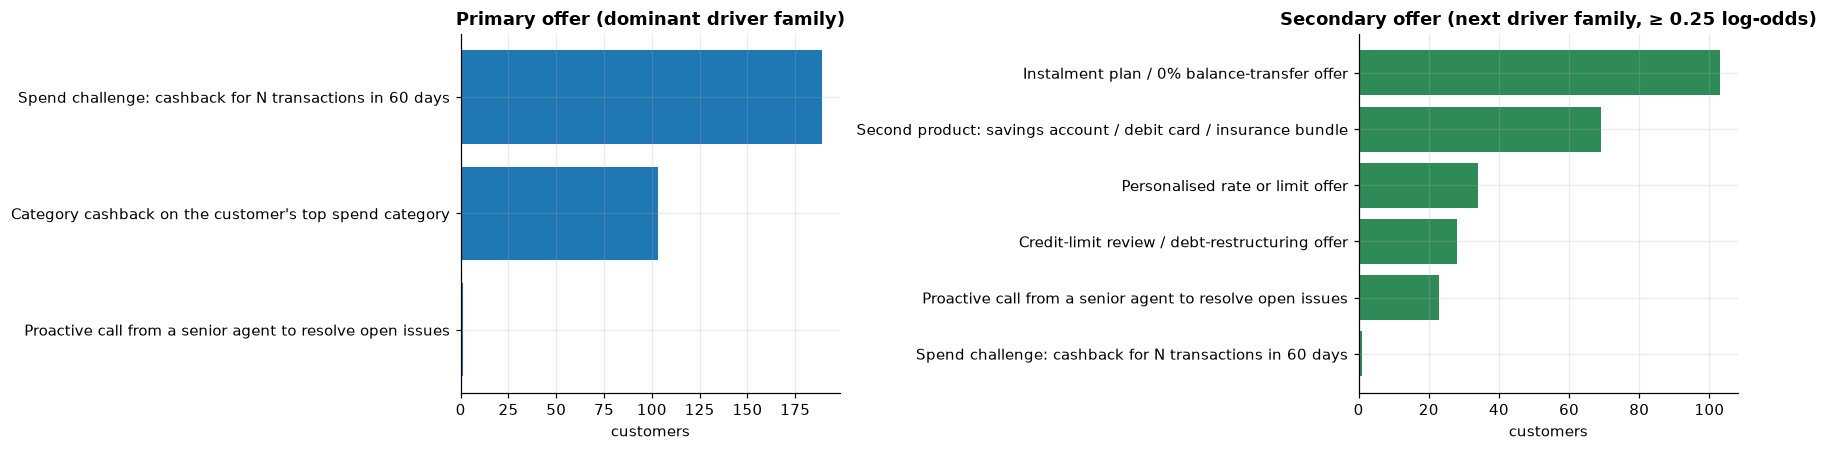

In [5]:
prim = campaign.groupby("offer").size().sort_values()
sec = campaign.loc[campaign.secondary_family != "none"].groupby("secondary_offer").size().sort_values()
fig, axes = plt.subplots(1, 2, figsize=(16, 4.2))
axes[0].barh(prim.index, prim.values, color=ACCENT)
axes[0].set(title="Primary offer (dominant driver family)", xlabel="customers")
axes[1].barh(sec.index, sec.values, color=GOOD)
axes[1].set(title="Secondary offer (next driver family, ≥ 0.25 log-odds)", xlabel="customers")
fig.tight_layout()
save(fig, "nba_actions")
plt.show()

**Reading the result.** For almost every at-risk customer the dominant
signal is **low or falling usage**, so the primary offer is a reactivation
offer. The concrete reactivation offer still differs (transaction frequency
vs spend amount). Real personalisation happens in the **secondary** layer:
zero-balance customers get an instalment / balance-transfer offer,
maxed-out customers a credit-limit review, customers with few products a
second product, and frequent callers a service-recovery call.

## 3. Examples (what the CRM team would receive)

In [6]:
show = ["clientnum", "proba", "clv", "expected_profit", "offer", "secondary_offer", "top3_drivers"]
examples = pd.concat([campaign.groupby("offer").head(1),
                      campaign[campaign.secondary_family != "none"].groupby("secondary_offer").head(1)])
examples.drop_duplicates("clientnum")[show].round(2)

,clientnum,proba,clv,expected_profit,offer,secondary_offer,top3_drivers
105,759584958,0.99,1030.08,219.67,Category cashback on the customer's top spend category,Personalised rate or limit offer,"avg_trans_amt, total_trans_amt, total_trans_ct"
37,716136333,1.00,836.85,173.68,Spend challenge: cashback for N transactions in 60 days,Credit-limit review / debt-restructuring offer,"total_trans_ct, total_trans_amt, total_revolving_bal"
119,718152333,0.99,150.00,1.98,Proactive call from a senior agent to resolve open issues,Spend challenge: cashback for N transactions in 60 days,"contacts_count_12_mon, total_trans_ct, total_revolving_bal"
0,715321008,1.00,991.08,212.53,Category cashback on the customer's top spend category,Credit-limit review / debt-restructuring offer,"avg_trans_amt, total_trans_amt, total_trans_ct"
247,714615258,0.98,920.10,189.51,Category cashback on the customer's top spend category,Second product: savings account / debit card / insurance bundle,"avg_trans_amt, total_trans_ct, total_trans_amt"
204,709444983,0.99,773.40,155.75,Spend challenge: cashback for N transactions in 60 days,Proactive call from a senior agent to resolve open issues,"total_trans_ct, total_amt_chng_q4_q1, total_ct_chng_q4_q1"
191,716506083,1.00,308.73,41.81,Category cashback on the customer's top spend category,Instalment plan / 0% balance-transfer offer,"avg_trans_amt, total_trans_ct, total_trans_amt"


## 4. Cross-sell pool *outside* the risk segment
Customers who are **not** at risk but hold only 1–2 products are the classic
cross-sell pool: they are stable, so a second product is a growth play
rather than a rescue. Sized here for completeness.

In [7]:
non_target = test[test.target == 0]
pool = non_target[non_target.total_relationship_count <= 2]
print(f"Low-risk customers with 1-2 products: {len(pool)} of {len(non_target)} "
      f"({len(pool) / len(non_target):.1%}); their churn rate: {pool.churned.mean():.1%}")

Low-risk customers with 1-2 products: 347 of 1733 (20.0%); their churn rate: 2.0%


## 5. How to validate (links to notebook 04)
* Multi-arm test inside the targeted segment: **control** vs
  **generic retention offer** vs **SHAP-driven next-best-action**. The key
  question is whether *personalising* the offer by driver beats a generic one.
* Secondary metric for cross-sell arms: product take-up within 60 days.
* Guardrail: offer cost per retained customer must stay below CLV.

**Limitations.** SHAP explains the *model*, not the causal mechanism: a
customer flagged "few products" may not want a second product. The mapping
is a sensible starting point that must earn its place experimentally.